In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
Path("../docs/images").mkdir(parents=True, exist_ok=True)
sales = pd.read_parquet("../data/processed/sales_daily.parquet")
products = pd.read_parquet("../data/processed/products.parquet")

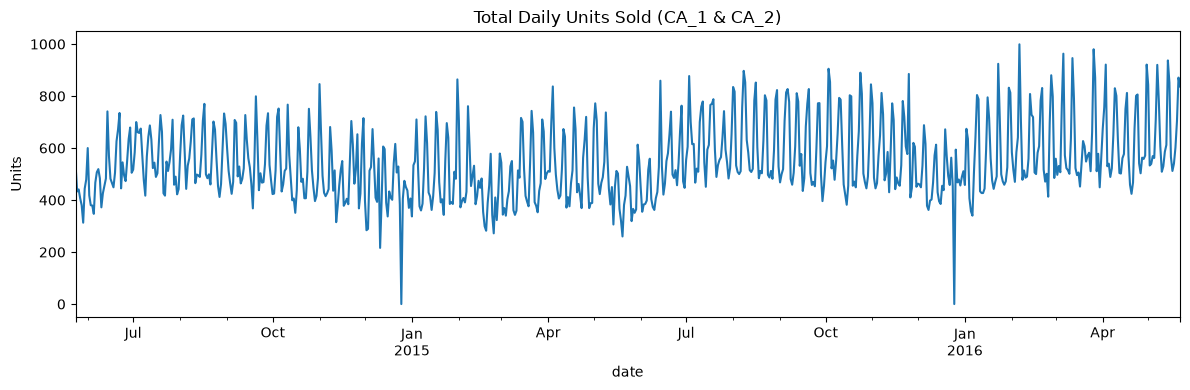

In [3]:
daily = sales.groupby("date")["units"].sum()
plt.figure(figsize=(12, 4))
daily.plot(title="Total Daily Units Sold (CA_1 & CA_2)")
plt.ylabel("Units")
plt.tight_layout()
plt.savefig("../docs/images/01_daily_units.png", dpi=150)
plt.show()

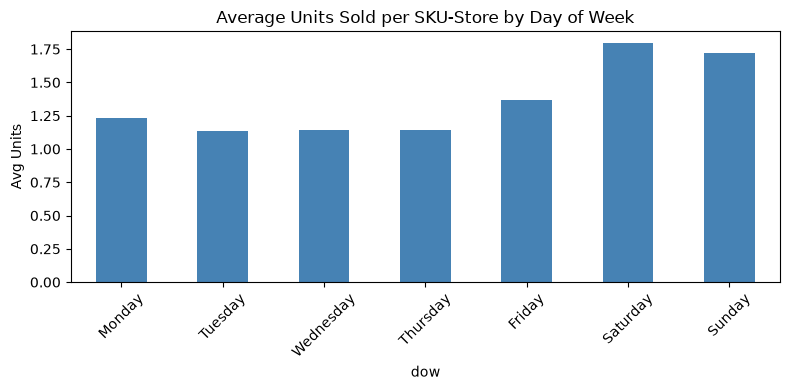

In [4]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = (
    sales.assign(dow=sales["date"].dt.day_name())
    .groupby("dow")["units"]
    .mean()
    .reindex(order)
)

plt.figure(figsize=(8, 4))
dow.plot(
    kind="bar",
    title="Average Units Sold per SKU-Store by Day of Week",
    color="steelblue",
)
plt.ylabel("Avg Units")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../docs/images/02_day_of_week.png", dpi=150)
plt.show()

#### Share of Zero-Sales Days per Category

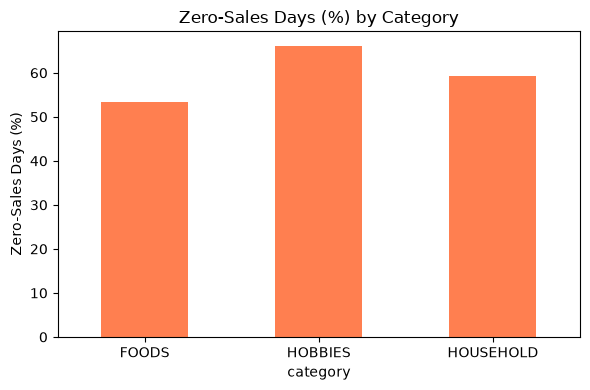

category
FOODS        53.349008
HOBBIES      66.116336
HOUSEHOLD    59.269066
Name: is_zero, dtype: float64


In [5]:
merged = sales.merge(products[["sku_id", "category"]], on="sku_id")
zero_share = (
    merged.assign(is_zero=merged["units"] == 0).groupby("category")["is_zero"].mean()
    * 100
)

plt.figure(figsize=(6, 4))
zero_share.plot(kind="bar", title="Zero-Sales Days (%) by Category", color="coral")
plt.ylabel("Zero-Sales Days (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../docs/images/03_zero_sales_share.png", dpi=150)
plt.show()
print(zero_share)

#### Price Changes for 3 Example Products

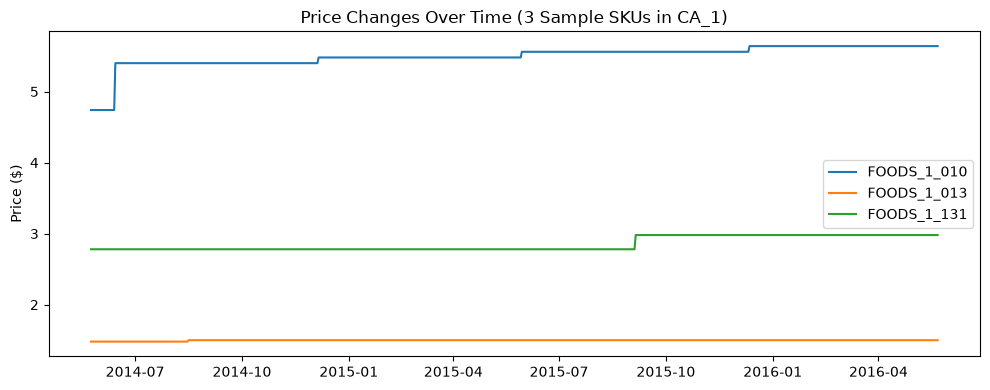

In [6]:
varying_skus = sales.groupby("sku_id")["price"].nunique()
example_skus = varying_skus[varying_skus > 1].index[:3]

plt.figure(figsize=(10, 4))
for sku in example_skus:
    sub = sales[(sales["sku_id"] == sku) & (sales["location_id"] == "CA_1")]
    plt.plot(sub["date"], sub["price"], label=sku)
plt.title("Price Changes Over Time (3 Sample SKUs in CA_1)")
plt.ylabel("Price ($)")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/images/04_price_changes.png", dpi=150)
plt.show()

#### Units on SNAP Days vs Other Days

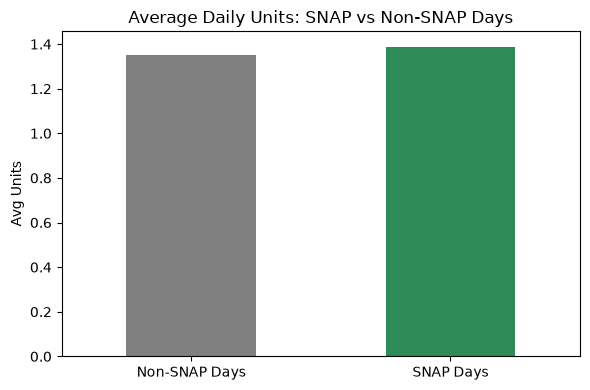

Non-SNAP Days    1.350041
SNAP Days        1.387894
Name: units, dtype: float64


In [7]:
snap_cmp = sales.groupby("snap")["units"].mean()
snap_cmp.index = ["Non-SNAP Days", "SNAP Days"]

plt.figure(figsize=(6, 4))
snap_cmp.plot(
    kind="bar",
    title="Average Daily Units: SNAP vs Non-SNAP Days",
    color=["gray", "seagreen"],
)
plt.ylabel("Avg Units")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../docs/images/05_snap_comparison.png", dpi=150)
plt.show()
print(snap_cmp)